In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
words = open('/content/drive/MyDrive/Andrej_Karpathy_Zero_To_Hero_neural_network/names.txt', 'r').read().splitlines()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
#local 
words = open('names.txt', 'r').read().splitlines()

In [3]:
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [4]:
len(words)

32033

In [5]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [6]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
# X = Input to the neural network
# Y = Label
X_test, Y_test = [], []
for w in words[:5]:

  print(w)
  # Initialize the context window with "..." (represented by index 0)
  # This erves as the padding before the actual word starts
  context = [0] * block_size
  print(context)
  # iTERATE THROUGH EACH CHARACTER IN THE WORD, APPENDING "." at the end
  # The "." acts as the special "End of word" token
  for ch in w + '.':
    ix = stoi[ch] # Convert the current character to its integer
    X_test.append(context) # Append the current sliding window character
    Y_test.append(ix) # Append the current character (the prediction)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    # Update the context window for the next iteration:
    # Remove the first character (Crop) and add the new character index to the end
    context = context[1:] + [ix] # crop and append

X_tensor_test = torch.tensor(X_test)
Y_tensor_test = torch.tensor(Y_test)

emma
[0, 0, 0]
... ---> e
..e ---> m
.em ---> m
emm ---> a
mma ---> .
olivia
[0, 0, 0]
... ---> o
..o ---> l
.ol ---> i
oli ---> v
liv ---> i
ivi ---> a
via ---> .
ava
[0, 0, 0]
... ---> a
..a ---> v
.av ---> a
ava ---> .
isabella
[0, 0, 0]
... ---> i
..i ---> s
.is ---> a
isa ---> b
sab ---> e
abe ---> l
bel ---> l
ell ---> a
lla ---> .
sophia
[0, 0, 0]
... ---> s
..s ---> o
.so ---> p
sop ---> h
oph ---> i
phi ---> a
hia ---> .


In [7]:
X_tensor_test.shape,X_tensor_test.dtype,Y_tensor_test.shape,Y_tensor_test.dtype

(torch.Size([32, 3]), torch.int64, torch.Size([32]), torch.int64)

In [8]:
X_tensor_test

tensor([[ 0,  0,  0],
        [ 0,  0,  5],
        [ 0,  5, 13],
        [ 5, 13, 13],
        [13, 13,  1],
        [ 0,  0,  0],
        [ 0,  0, 15],
        [ 0, 15, 12],
        [15, 12,  9],
        [12,  9, 22],
        [ 9, 22,  9],
        [22,  9,  1],
        [ 0,  0,  0],
        [ 0,  0,  1],
        [ 0,  1, 22],
        [ 1, 22,  1],
        [ 0,  0,  0],
        [ 0,  0,  9],
        [ 0,  9, 19],
        [ 9, 19,  1],
        [19,  1,  2],
        [ 1,  2,  5],
        [ 2,  5, 12],
        [ 5, 12, 12],
        [12, 12,  1],
        [ 0,  0,  0],
        [ 0,  0, 19],
        [ 0, 19, 15],
        [19, 15, 16],
        [15, 16,  8],
        [16,  8,  9],
        [ 8,  9,  1]])

In [9]:
Y_tensor_test

tensor([ 5, 13, 13,  1,  0, 15, 12,  9, 22,  9,  1,  0,  1, 22,  1,  0,  9, 19,
         1,  2,  5, 12, 12,  1,  0, 19, 15, 16,  8,  9,  1,  0])

In [10]:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
# X = Input to the neural network
# Y = Label
X, Y = [], []
for w in words:

  #print(w)
  context = [0] * block_size # if block_size = 3, the context will be [0,0,0]
  for ch in w + '.':
    ix = stoi[ch]
    X.append(context)
    Y.append(ix)
    #print(''.join(itos[i] for i in context), '--->', itos[ix])
    context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

In [11]:
X.shape, X.dtype, Y.shape, Y.dtype

(torch.Size([228146, 3]), torch.int64, torch.Size([228146]), torch.int64)

In [12]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size #[0,0,0]
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])


torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [13]:
C = torch.randn((27, 2))

In [14]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [15]:
import torch

# Define the Embedding Table (Matrix C)
C = torch.tensor([
    [0.1, 0.1],  # Index 0
    [0.2, 0.2],  # Index 1
    [0.3, 0.3]   # Index 2
])

# Define the Input Batch (Matrix X) - Shape (2, 3)
X = torch.tensor([
    [0, 2, 1],
    [2, 0, 0]
])

# Perform the Lookup
result = C[X]
print(f"C's shape --> {C.shape}")
print(result)
print("Shape:", result.shape)

C's shape --> torch.Size([3, 2])
tensor([[[0.1000, 0.1000],
         [0.3000, 0.3000],
         [0.2000, 0.2000]],

        [[0.3000, 0.3000],
         [0.1000, 0.1000],
         [0.1000, 0.1000]]])
Shape: torch.Size([2, 3, 2])


In [16]:
emb

tensor([[[-0.4326,  0.8583],
         [-0.4326,  0.8583],
         [-0.4326,  0.8583]],

        [[-0.4326,  0.8583],
         [-0.4326,  0.8583],
         [-1.1328, -0.9168]],

        [[-0.4326,  0.8583],
         [-1.1328, -0.9168],
         [-0.2670,  1.2278]],

        ...,

        [[ 0.0350, -0.6101],
         [ 0.0350, -0.6101],
         [ 0.0453,  0.3265]],

        [[ 0.0350, -0.6101],
         [ 0.0453,  0.3265],
         [ 0.0350, -0.6101]],

        [[ 0.0453,  0.3265],
         [ 0.0350, -0.6101],
         [ 2.1888, -1.5628]]])

In [17]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [18]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1)

In [19]:
h

tensor([[-0.7948,  0.8546, -0.6806,  ..., -0.4451,  0.2997,  0.6518],
        [-0.5506, -0.3977, -0.6570,  ..., -0.8681, -0.8922,  0.9898],
        [-0.9954,  0.6732, -0.5602,  ...,  0.9694,  0.8404, -0.7953],
        ...,
        [-0.2344,  0.7407, -0.7648,  ...,  0.9247, -0.7509, -0.8889],
        [ 0.5307,  0.6149, -0.6595,  ...,  0.8052, -0.9756,  0.1255],
        [ 0.9181,  0.9867,  0.9813,  ...,  0.9964, -0.9984, -0.9292]])

In [20]:
W2 = torch.randn((100,27))
b2 = torch.randn(27)

In [21]:
logits = h @ W2 + b2

In [22]:
# 228146 because it contains all the worlds divided in 3 block
# check the block of code executed before
# this contains the logits for every piece that 27 means
# the probability of 27 characters that will appears after we know the context for first 3 character
logits.shape

torch.Size([228146, 27])

In [23]:
counts = logits.exp()

In [24]:
prob = counts / counts.sum(1, keepdims=True)

In [25]:
prob.shape

torch.Size([228146, 27])

In [26]:
# to check if the operation was correct, so the sum of the probability in
# one row should be 1
prob[0].sum()

tensor(1.0000)

In [42]:
X.shape[0], X.shape, Y.shape

(36, torch.Size([36, 3]), torch.Size([36]))

In [43]:
prob[torch.arange(X.shape[0]), Y]

tensor([5.6799e-09, 8.5051e-15, 1.0728e-05, 8.9248e-07, 5.8261e-01, 1.3340e-15,
        3.2421e-12, 2.3119e-12, 3.1812e-10, 2.9066e-07, 1.9088e-02, 1.5961e-07,
        1.1281e-04, 1.0056e-03, 1.7149e-09, 9.4408e-06, 4.8239e-12, 9.1633e-17,
        8.4562e-07, 6.1520e-08, 1.2476e-02, 2.8066e-16, 8.5761e-01, 1.2594e-10,
        6.6622e-10, 4.2872e-13, 4.4482e-04, 8.5761e-01, 2.8022e-10, 7.3586e-13,
        4.7449e-19, 1.2822e-07, 1.3828e-08, 3.7091e-03, 6.8245e-05, 8.5187e-03])

In [44]:
# prob[torch.arange(X.shape[0]), Y] --> gives the current probabilities
# as assigned by this neural network with this setting of weights
loss = -prob[torch.arange(X.shape[0]), Y].log().mean()
loss

tensor(17.4809)

Made respectable

In [31]:
# For testing purpose:
# build the dataset

block_size = 3 # context length: how many characters do we take to predict the next one?
# X = Input to the neural network
# Y = Label
X, Y = [], []
for w in words[:5]:

  print(w)
  # Initialize the context window with "..." (represented by index 0)
  # This erves as the padding before the actual word starts
  context = [0] * block_size
  print(context)
  # iTERATE THROUGH EACH CHARACTER IN THE WORD, APPENDING "." at the end
  # The "." acts as the special "End of word" token
  for ch in w + '.':
    ix = stoi[ch] # Convert the current character to its integer
    X.append(context) # Append the current sliding window character
    Y.append(ix) # Append the current character (the prediction)
    print(''.join(itos[i] for i in context), '--->', itos[ix])
    # Update the context window for the next iteration:
    # Remove the first character (Crop) and add the new character index to the end
    context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)

yuheng
[0, 0, 0]
... ---> y
..y ---> u
.yu ---> h
yuh ---> e
uhe ---> n
hen ---> g
eng ---> .
diondre
[0, 0, 0]
... ---> d
..d ---> i
.di ---> o
dio ---> n
ion ---> d
ond ---> r
ndr ---> e
dre ---> .
xavien
[0, 0, 0]
... ---> x
..x ---> a
.xa ---> v
xav ---> i
avi ---> e
vie ---> n
ien ---> .
jori
[0, 0, 0]
... ---> j
..j ---> o
.jo ---> r
jor ---> i
ori ---> .
juanluis
[0, 0, 0]
... ---> j
..j ---> u
.ju ---> a
jua ---> n
uan ---> l
anl ---> u
nlu ---> i
lui ---> s
uis ---> .


In [32]:
X.shape, Y.shape # dataset

(torch.Size([36, 3]), torch.Size([36]))

In [33]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 100), generator=g)
b1 = torch.randn(100, generator=g)
W2 = torch.randn((100, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

In [34]:
sum(p.nelement() for p in parameters) # number of parameters in total

3481

In [35]:
emb = C[X] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
counts = logits.exp()
# softmax
# probability of each words appears after a specific context ("3 letters for example")
prob = counts / counts.sum(1, keepdim=True)
loss = -prob[torch.arange(X.shape[0]), Y].log().mean()
loss

tensor(17.4809)

In [36]:
prob[0]


tensor([2.5218e-09, 2.0283e-10, 2.1459e-04, 8.7084e-11, 2.3119e-12, 1.5213e-14,
        9.3108e-19, 8.3789e-06, 4.5310e-09, 1.4206e-01, 8.5761e-01, 5.2101e-12,
        1.7917e-10, 1.8797e-10, 9.4676e-05, 1.0823e-10, 3.5813e-09, 1.0154e-07,
        2.7855e-07, 2.6851e-09, 2.2371e-11, 3.2192e-09, 4.8182e-12, 2.0270e-11,
        9.4408e-06, 5.6799e-09, 3.4497e-06])

In [37]:
for p in parameters:
    p.requires_grad = True

In [38]:
# training on full dataset
for _ in range(10):
    # forward pass
    emb = C[X] # (228146, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
    logits = h @ W2 + b2 # (228146, 27)
    # calcualte the loss
    loss = F.cross_entropy(logits, Y)
    print(loss.item())
    #backward pass
    for p in parameters:
        # zero gradient
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -0.1 * p.grad


17.480852127075195
14.495278358459473
12.29909896850586
10.703853607177734
9.438857078552246
8.386002540588379
7.486644268035889
6.681829929351807
5.976032733917236
5.379570484161377


In [39]:
loss.item()

5.379570484161377

In [40]:
# training on mini-batches dataset
for _ in range(100):

    #mini batch construct
    ix = torch.randint(0,X.shape[0],(32,))


    # forward pass
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
    logits = h @ W2 + b2 # (228146, 27)
    # calcualte the loss
    # Y[ix] choose the corresponding label
    loss = F.cross_entropy(logits, Y[ix])
    #backward pass
    for p in parameters:
        # zero gradient
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -0.01 * p.grad

print(loss.item())


1.5389299392700195


In [41]:
# evaluate the loss on full dataset
emb = C[X] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Y)
loss

tensor(2.1811, grad_fn=<NllLossBackward0>)

# Find the optimal learning rate

In [45]:
# Create 1000 exponents equally spaced between -3 and 0
# -3 corresponds to 10^-3 (0.001)
# 0 corresponds to 10^0 (1.0)
lre = torch.linspace(-3,0,1000)

# Calculate the actual Learning Rates using these exponents
lrs = 10**lre # cretes a tensor with same shape of lre
# while elements contains 10**lre


In [46]:
# Lists to store the history so we can plot them later
lri = []   # To store the Learning Rate exponent used
lossi = [] # To store the Loss resulting from that Learning Rate

for i in range(1000):

    # 1. Mini-batch construction (Randomly pick 32 examples)
    ix = torch.randint(0, X.shape[0], (32,))

    # 2. Forward Pass
    emb = C[X[ix]]
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Y[ix])

    # 3. Backward Pass (Zero grad, then Calculate grad)
    for p in parameters:
        p.grad = None
    loss.backward()

    # 4. Update Parameters DYNAMICALLY
    # Use the specific learning rate for this step (i)
    lr = lrs[i] #lrs is a list of learinig rate ranging from 0.001 to 1
    for p in parameters:
        p.data += -lr * p.grad

    # 5. Record the stats
    lri.append(lre[i])       # Record the exponent (x-axis)
    lossi.append(loss.item()) # Record the loss (y-axis)

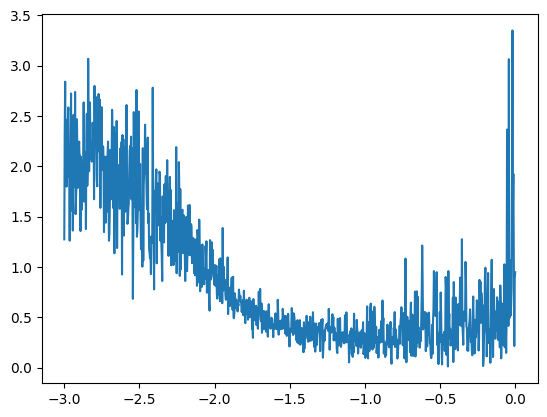

In [47]:
plt.plot(lri, lossi)

# Train-validation-test split

In [48]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 2), generator=g)
W1 = torch.randn((6, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
sum(p.nelement() for p in parameters) # number of parameters in total

6881

In [49]:
for p in parameters:
    p.requires_grad = True

In [50]:
# training on mini-batches dataset with train set
for _ in range(10000):

    #mini batch construct
    ix = torch.randint(0,Xtr.shape[0],(32,))


    # forward pass
    emb = C[Xtr[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
    logits = h @ W2 + b2 # (228146, 27)
    # calcualte the loss
    # Y[ix] choose the corresponding label
    loss = F.cross_entropy(logits, Ytr[ix])
    #backward pass
    for p in parameters:
        # zero gradient
        p.grad = None
    loss.backward()
    #update
    for p in parameters:
        p.data += -0.1 * p.grad

print(loss.item())


2.4131362438201904


In [51]:
# evaluate the loss on full dataset
emb = C[Xdev] # (228146, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (228146, 100)
logits = h @ W2 + b2 # (228146, 27)
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.6042, grad_fn=<NllLossBackward0>)

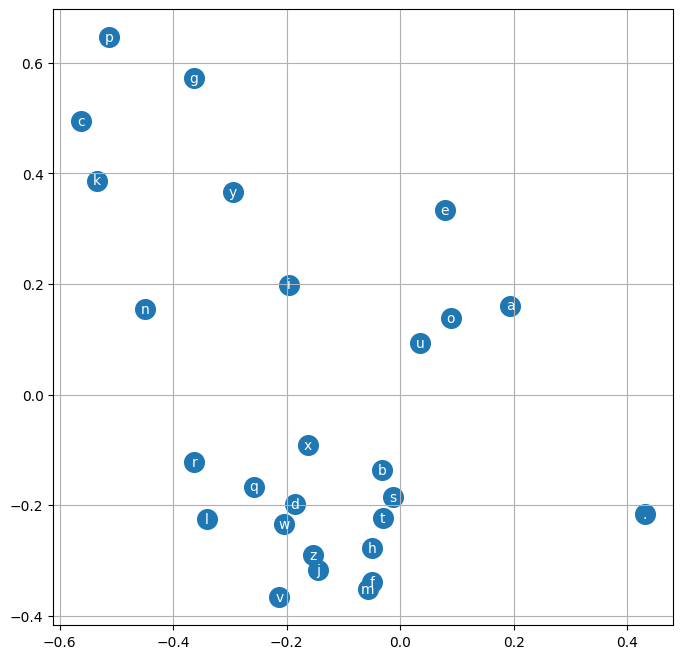

In [52]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [54]:


# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(5):

    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break

    print(''.join(itos[i] for i in out))

carlah.
alille.
lhi.
mrix.
latcannahsane.
